# Brooklyn property market research — Python analysis

**Question:** Which recorded sales are suitable for further comparable-sale research, and how sensitive are the results to our screening choices?

This notebook shows source verification, exploratory analysis, cleaning decisions, SQL reconciliation, charts and interpretation. Streamlit is optional presentation; the analysis below runs independently. Official records are not verified appraisals. Sale-date cutoff: 2025-12-31; annual files were published later.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/brooklyn_multifamily_sales.csv').exists(), 'Open from the repository or notebooks directory'
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'src'))
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})


## 1. Verify and inspect the original extract
Retain all source rows, including zero-consideration transfers. Do not fill missing prices with estimated values.

In [2]:
from property_research.data import digest, screen
raw = pd.read_csv(ROOT/'data/brooklyn_multifamily_sales.csv', keep_default_na=False)
registry = json.loads((ROOT/'data/sources.json').read_text())
assert digest(ROOT/'data/brooklyn_multifamily_sales.csv') == registry['snapshot_sha256']
assert len(raw) == sum(s['scope_rows'] for s in registry['sources'])
display(pd.DataFrame([{'source':s['source_id'], 'records':s['scope_rows'], 'url':s['url']} for s in registry['sources']]))
display(raw[['sale_price','gross_square_feet','residential_units','year_built']].describe().round(2))
print('Duplicate source IDs:', raw.record_id.duplicated().sum())


Duplicate source IDs: 0


,source,records,url
0,nyc_dof_brooklyn_2024,1161,https://www.nyc.gov/assets/finance/downloads/p...
1,nyc_dof_brooklyn_2025,1212,https://www.nyc.gov/assets/finance/downloads/p...


,sale_price,gross_square_feet,residential_units
count,2373.00,2373.00,2373.00
mean,1313186.82,5304.70,6.37
std,2965001.27,4708.44,5.47
min,0.00,0.00,0.00
25%,0.00,3200.00,4.00
50%,50000.00,4070.00,5.00
75%,1690000.00,5500.00,6.00
max,55000000.00,56000.00,73.00


## 2. Apply documented quality screens
Primary reasons reconcile to the input. Other reasons may overlap; their counts cannot be added as distinct records. Thresholds are research assumptions, not appraisal standards.

1,045 retained of 2,373; 1,328 preserved for review.


,records
primary_reason,
zero_or_negative_price,1072
eligible,1045
low_consideration_review,121
possible_multi_parcel_consideration,117
ppsf_outside_screen,8
mixed_or_invalid_units,4
missing_or_nonfinite_numeric,4
gross_area_outside_screen,2


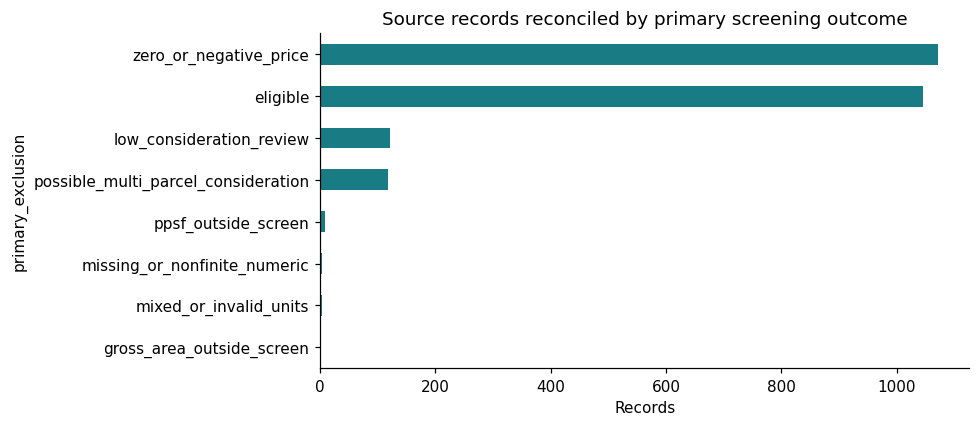

In [3]:
cfg = json.loads((ROOT/'config/research.json').read_text())
clean = screen(raw, cfg)
eligible = clean.loc[clean.eligible].copy()
reasons = clean.primary_exclusion.replace('', 'eligible').value_counts()
assert reasons.sum() == len(raw)
display(reasons.rename_axis('primary_reason').to_frame('records'))
reasons.sort_values().plot.barh(color='#197b83', title='Source records reconciled by primary screening outcome')
plt.xlabel('Records'); plt.tight_layout(); plt.show()
print(f'{len(eligible):,} retained of {len(raw):,}; {(~clean.eligible).sum():,} preserved for review.')


## 3. Explore property classes and transaction mix
Compare median and quartiles instead of relying only on a mean. Different classes and sales mixes are not directly interchangeable.

,sales,median_price,median_area,median_ppsf
building_class_at_time_of_sale,,,,
C1,226,2325000.0,7260.0,241.43
C2,316,1267500.0,4548.0,275.20
C3,503,1700000.0,3215.0,527.07


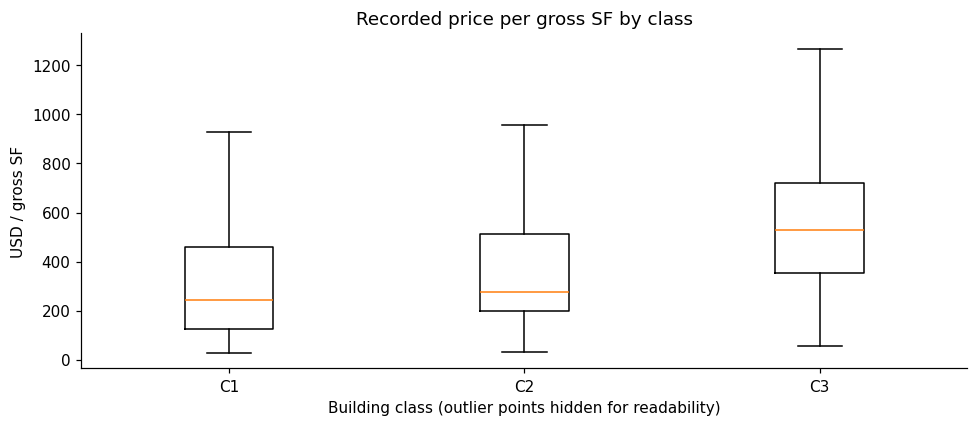

In [4]:
profile = eligible.groupby('building_class_at_time_of_sale').agg(sales=('record_id','size'), median_price=('sale_price','median'), median_area=('gross_square_feet','median'), median_ppsf=('price_per_sqft','median'))
display(profile.round(2))
fig, ax = plt.subplots()
classes = sorted(eligible.building_class_at_time_of_sale.unique())
ax.boxplot([eligible.loc[eligible.building_class_at_time_of_sale.eq(c),'price_per_sqft'] for c in classes], tick_labels=classes, showfliers=False)
ax.set(title='Recorded price per gross SF by class', ylabel='USD / gross SF', xlabel='Building class (outlier points hidden for readability)')
plt.tight_layout(); plt.show()


## 4. SQL trends and independent reconciliation
DuckDB is the SQL engine called from Python. These are observed quarterly medians, not appreciation estimates.

,quarter,class,sales,median_ppsf
0,2024-01-01,C1,16,522.52
1,2024-01-01,C2,38,298.26
2,2024-01-01,C3,62,504.08
3,2024-04-01,C1,29,193.42
4,2024-04-01,C2,30,261.02
5,2024-04-01,C3,64,524.17
6,2024-07-01,C1,23,218.59
7,2024-07-01,C2,31,300.00
8,2024-07-01,C3,61,489.96


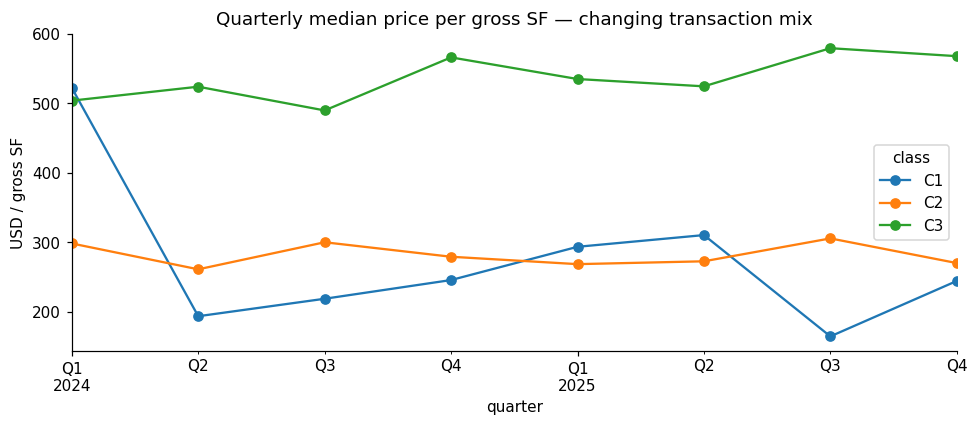

In [5]:
import duckdb
with duckdb.connect() as con:
    con.register('sales', eligible)
    trends = con.execute("""SELECT date_trunc('quarter', sale_date) AS quarter,
      building_class_at_time_of_sale AS class, COUNT(*) AS sales,
      MEDIAN(price_per_sqft) AS median_ppsf FROM sales GROUP BY 1,2 ORDER BY 1,2""").df()
assert trends.sales.sum() == len(eligible)
display(trends.head(9).round(2))
trends.pivot(index='quarter',columns='class',values='median_ppsf').plot(marker='o',title='Quarterly median price per gross SF — changing transaction mix')
plt.ylabel('USD / gross SF'); plt.tight_layout(); plt.show()


## 5. Select and inspect comparable records
Hold the subject parcel out of the pool. Rank by size, age, recency and units, not by price. Every selected record retains its source row.

In [6]:
from property_research.comparables import choose_example, select_comparables
subject = choose_example(clean,cfg)
comps, audit, summary = select_comparables(clean,subject,cfg)
display(pd.Series(subject).to_frame('example subject'))
display(comps[['address','sale_date','sale_price','gross_square_feet','price_per_sqft','source_id','source_row']].round(2))
assert not comps.bbl.eq(subject['bbl']).any()
assert comps.bbl.is_unique
print(summary)


{'status': 'APPRAISER REVIEW REQUIRED', 'count': 5, 'median_ppsf': 351.78236397748594, 'q25_ppsf': 223.5772357723577, 'q75_ppsf': 359.59974984365226}


,example subject
record_id,26d040ff0ce4583b8c79
source_id,nyc_dof_brooklyn_2025
source_row,13305
bbl,3-04599-0030
address,48 ROCKAWAY PARKWAY
neighborhood,FLATBUSH-NORTH
building_class_at_time_of_sale,C3
gross_square_feet,3214.0
year_built,1930
residential_units,4


,address,sale_date,sale_price,gross_square_feet,price_per_sqft,source_id,source_row
1975,371 EAST 95 STREET,2025-11-19,1285000.0,3198.0,401.81,nyc_dof_brooklyn_2025,13346
1981,409 EAST 96TH STREET,2025-10-20,715000.0,3198.0,223.58,nyc_dof_brooklyn_2025,13352
1972,309 ROCKAWAY PARKWAY,2025-10-20,1125000.0,3198.0,351.78,nyc_dof_brooklyn_2025,13343
1947,119 ROCKAWAY PARKWAY,2025-10-09,516000.0,3198.0,161.35,nyc_dof_brooklyn_2025,13318
1942,159 EAST 95TH ST,2025-09-26,1150000.0,3198.0,359.60,nyc_dof_brooklyn_2025,13313


## 6. Sensitivity: keep the same subject and vary size tolerance
A result that changes with reasonable analyst choices needs explicit review. Do not choose a tolerance to obtain a desired price. The size weight is normalized by the chosen tolerance in each scenario.

In [7]:
sensitivity=[]
for tolerance in [0.15,0.20,0.30,0.40]:
    alternative={**cfg,'max_size_difference':tolerance}
    selected, _, stats=select_comparables(clean,subject,alternative)
    sensitivity.append({'size_tolerance':tolerance, 'comparables':len(selected), 'median_ppsf':stats['median_ppsf'], 'status':stats['status'], 'selected_ids':', '.join(selected.record_id)})
display(pd.DataFrame(sensitivity).drop(columns='selected_ids').round(2))


,size_tolerance,comparables,median_ppsf,status
0,0.15,5,351.78,APPRAISER REVIEW REQUIRED
1,0.20,5,351.78,APPRAISER REVIEW REQUIRED
2,0.30,5,351.78,APPRAISER REVIEW REQUIRED
3,0.40,5,351.78,APPRAISER REVIEW REQUIRED


## 7. Findings and actions
The following summary is calculated from the data rather than typed as an assumed business result.

In [8]:
from IPython.display import Markdown
package_count = clean.exclusion_reasons.str.contains('possible_multi_parcel_consideration').sum()
medians = pd.DataFrame(sensitivity).median_ppsf.dropna()
display(Markdown(f"""- **Coverage:** {len(eligible):,} / {len(raw):,} transactions pass the documented research screens.
- **Package-sale review:** {package_count:,} records share same-date consideration across distinct parcels in the scope. Verify allocation before dividing consideration by one property's area.
- **Example evidence:** {len(comps)} selected comparables for {subject['address']}; the median is ${summary['median_ppsf']:,.2f} per gross SF.
- **Sensitivity:** observed medians across tested size tolerances span ${medians.min():,.2f}–${medians.max():,.2f} per gross SF. These are scenario summaries, not a subject value range.
- **Next action:** confirm deed terms, rights, condition and area before an appraiser accepts these comparisons. No time, condition or income adjustment is fabricated."""))


- **Coverage:** 1,045 / 2,373 transactions pass the documented research screens.
- **Package-sale review:** 118 records share same-date consideration across distinct parcels in the scope. Verify allocation before dividing consideration by one property's area.
- **Example evidence:** 5 selected comparables for 48 ROCKAWAY PARKWAY; the median is $351.78 per gross SF.
- **Sensitivity:** observed medians across tested size tolerances span $351.78–$351.78 per gross SF. These are scenario summaries, not a subject value range.
- **Next action:** confirm deed terms, rights, condition and area before an appraiser accepts these comparisons. No time, condition or income adjustment is fabricated.

## Limits
One provider, no inspection, no independent arms-length confirmation, no rent/NOI evidence and no appraisal opinion. Administrative neighborhoods are not geocoded distance bands. This is descriptive analysis; no predictive accuracy or causal effect is claimed.